# 进入非线性最小二乘

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

直线拟合可以一次求解，指数衰减的速率却出现在指数里。我们的办法不是寻找一个万能闭式公式，而是在当前参数附近，把曲线暂时近似成直线，再决定走多远。

## 残差向量的局部模型

设$r:\mathbb R^n\to\mathbb R^m$连续可微，其雅可比为$J_{ij}=\partial r_i/\partial x_j$。一个小步长$h$给出

$$r(x+h)\approx r(x)+J(x)h.$$

因此局部目标模型是$q(h)=\tfrac12\|r+Jh\|^2$。它是关于$h$的线性最小二乘，即使原问题关于$x$是非线性的。

目标的梯度和精确Hessian分别为

$$g=J^Tr,\qquad
H=J^TJ+\sum_{i=1}^m r_i\,\nabla^2r_i.$$

后面一项包含残差的二阶导数。残差很小或模型在附近近似线性时，它可能较小；若残差很大，就不能未经检查把它忽略。

## 亲手写出指数模型的雅可比

对$f(t;x)=a\exp(-kt)+c$，参数顺序固定为$x=(a,k,c)^T$：

$$J_i=\begin{bmatrix}e^{-kt_i}&-at_i e^{-kt_i}&1\end{bmatrix}.$$

读清维度：每一行是一条观测，每一列是一个参数。最常见的错误是把$m\times n$转成$n\times m$，或忘记残差符号。

Jacobian shape: (30, 3)
largest derivative difference: 5.2015725060527984e-11


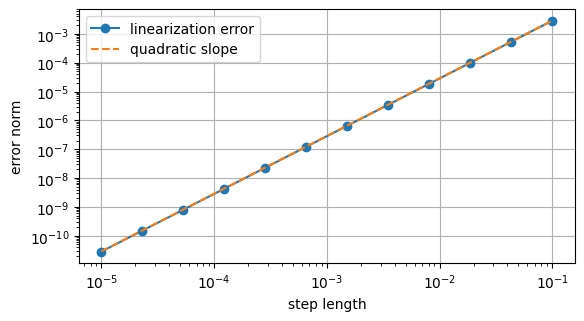

In [2]:
t = np.linspace(0, 4, 30)
p = np.array([2.5, .8, .4])
def model(p):
    a, k, c = p
    return a*np.exp(-k*t)+c
def jac(p):
    a, k, c = p
    e = np.exp(-k*t)
    return np.column_stack([e, -a*t*e, np.ones_like(t)])
J = jac(p)
numerical = finite_difference(model, p)
print('Jacobian shape:', J.shape)
print('largest derivative difference:', np.max(np.abs(J-numerical)))
assert np.allclose(J, numerical, rtol=1e-7, atol=1e-8)
direction = np.array([.3, -.2, .1])
steps = np.logspace(-5, -1, 12)
errors = [np.linalg.norm(model(p+h*direction)-model(p)-h*J@direction) for h in steps]
plt.loglog(steps, errors, 'o-', label='linearization error')
plt.loglog(steps, errors[-1]*(steps/steps[-1])**2, '--', label='quadratic slope')
plt.xlabel('step length'); plt.ylabel('error norm'); plt.legend(); plt.show()

图中小步长范围的误差约按$h^2$增长，这检验了线性化。步长太小时，浮点舍入会破坏这个规律。不是扰动越小，数值导数就一定越准确。

## 数值微分如何选步长

中心差分使用

$$J_{:,j}\approx
\frac{r(x+\delta_j e_j)-r(x-\delta_j e_j)}{2\delta_j}.$$

对足够光滑且无测量噪声的函数，截断误差通常为$O(\delta_j^2)$，舍入误差则随$\delta_j$缩小而增加。代码取$\delta_j=\epsilon^{1/3}\max(1,|x_j|)$是双精度下的实用起点，不适用于所有噪声和量化测量。

如果每次函数求值都来自真实仪器，差分中的测量噪声会被除以$\delta_j$，小扰动反而可能完全淹没有效信号。第15章将讨论重复采样、双侧扰动和量化平台。

## 练习与解答

练习：$r_i=a e^{-kt_i}+c-y_i$改为$y_i-a e^{-kt_i}-c$，梯度$J^Tr$是否改变？解答：$r$与$J$同时变号，梯度不变。

练习：当$a=0$时，$k$的局部可辨识性怎样？解答：雅可比的第二列全零，速率此时无法通过局部观测估计；这是模型信息不足，不是换一个求解器就会消失的问题。

练习：$g=0$是否证明全局最小？解答：不证明，它只说明一阶驻点；非线性目标可能有局部极小、极大或鞍点。